# Workbench — the whole `stochastics` package in one place

Run this notebook to check that every part imports, run the tests for any part, and try quick experiments
while you develop. Code is reloaded automatically when you save a file (`%autoreload 2`), and the tests
always run in a fresh process, so they see exactly what is on disk.

| part | what it is | tests |
|---|---|---|
| `physics` | particles, gravity/EM, composition collisions, energy ledger, policy lab | `tests/test_physics.py` |
| `baseline` | stochastic processes: random walk … GBM, OU, CIR, Poisson, SDE schemes, jumps, fBM, Hawkes | `tests/test_baseline.py` |
| `popdyn` | ecosystems, epidemics, rock-paper-scissors, wealth economies, segregation | `tests/test_popdyn.py` |
| `finance` | insurance & ruin, market models (v1–4), limit order book, agent-based exchange (v5–7), real-data benchmark | `tests/test_finance*.py` |

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd

import stochastics
from stochastics import dev, physics, baseline, popdyn, finance
from stochastics.finance import insurance, market, lob, exchange, realdata, benchmark

print('stochastics', stochastics.__version__, 'loaded from', stochastics.__file__)
dev.health()

stochastics 0.5.0 loaded from /home/claude/stochastics-lab/stochastics/__init__.py


,status,public names,modules,import (s),error
subpackage,,,,,
physics,ok,57,"_style, animation, collisions, engine, environ...",0.0,
baseline,ok,11,"combine, paths, processes",0.0,
popdyn,ok,29,"core, cyclic, ecosystem, epidemic, segregation...",0.0,
finance,ok,8,"_streams, agents, benchmark, exchange, insuran...",0.0,


## Tests

`dev.test()` runs everything; `dev.test('baseline')` runs one part; extra pytest arguments pass through,
e.g. `dev.test('popdyn', '-k', 'wealth')` or `dev.test('physics', '-x')` (stop at the first failure).

In [2]:
dev.test()

........................................................................ [ 36%]
........................................................................ [ 72%]
........................................................                 [100%]
=============================== warnings summary ===============================
tests/test_finance_benchmark.py::test_parallel_replicates_match_serial_ones
tests/test_finance_benchmark.py::test_parallel_replicates_match_serial_ones
tests/test_finance_benchmark.py::test_a_sweep_scores_every_series_and_summarises_by_asset_class
tests/test_finance_benchmark.py::test_a_sweep_scores_every_series_and_summarises_by_asset_class
tests/test_finance_benchmark.py::test_holdout_over_several_series_and_real_series_objects
tests/test_finance_benchmark.py::test_holdout_over_several_series_and_real_series_objects
  /usr/lib/python3.13/multiprocessing/popen_fork.py:73: DeprecationWarning: This process (pid=2402) is multi-threaded, use of fork() may lead to deadlocks 

0

In [3]:
dev.test('baseline', '-k', 'convolution or moments')

.............                                                            [100%]
13 passed, 11 deselected in 4.58s

[baseline] exit code 0 in 5.2s


0

## physics — quick check

In [4]:
from stochastics.physics import ParticleSystem, Environment, Gravity, Collisions, simulate

p = ParticleSystem.random(n=120, preset='em', dimension=2, seed=1)
r = simulate(p, Environment(law=Gravity(G=0.05), rules=[Collisions()]), steps=400, dt=0.01, record_every=10)
r.summary()

,value
metric,
simulated time,0 -> 4
steps x dt,400 x 0.01
runtime,0.08 s
particles (live),120 -> 1
events: merge,119
mass drift,-2.842e-14
charge drift,+3.553e-15
momentum drift |dp|,4.016e-14 (scale 45.1)
energy residual,+1.153e+00 (+1.02e-03 relative)


## baseline — quick check

final mean 0.1 | final std 10.159


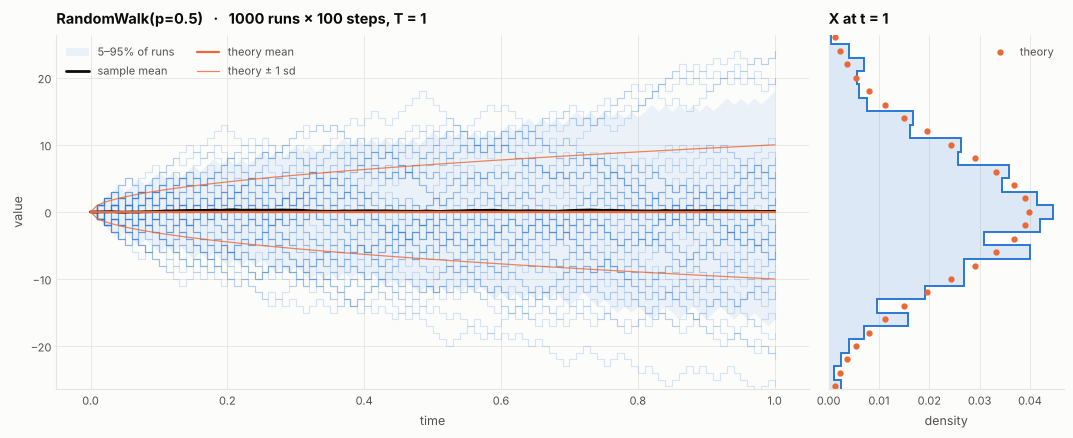

In [5]:
from stochastics.baseline import process, combine

X = process(t=100, n=1000, seed=1)
X.randomwalk()
print('final mean', round(X.mean.iloc[-1], 3), '| final std', round(X.std.iloc[-1], 3))
X.plot()

In [6]:
P = process(t=250, n=2000, seed=2)
S = combine([0.5, 0.2, 0.3], [P.gbm(mu=1, sigma=2), P.abm(mu=2, sigma=0.5), P.gbm(mu=1, sigma=3)])
S.describe()

,simulated,theory,z (mean)
"0.5·GBM(μ=1, σ=2) + 0.2·ABM(μ=2, σ=0.5) + 0.3·GBM(μ=1, σ=3) at t=1 (2000 runs)",,,
mean,3.029184,2.574625,0.870135
std,23.362449,74.074474,NaN
var,545.804009,5487.027674,NaN
skew,35.052999,NaN,NaN
excess kurtosis,1404.105408,NaN,NaN
min,0.165674,NaN,NaN
median,0.719095,NaN,NaN
max,958.782042,NaN,NaN


## popdyn — quick check

In [7]:
from stochastics.popdyn import Ecosystem, Economy

eco = Ecosystem(width=50, height=50, seed=3).run(400)
display(eco.totals())
econ = Economy(n=5000, seed=1).run(60)
econ.summary()

,total
grass eaten by rabbits (items),2.586600e+04
grass eaten by rabbits (energy),7.759800e+04
rabbits eaten by wolves (items),4.684000e+03
rabbits eaten by wolves (energy),3.378959e+04
rabbit births,5.449000e+03
wolf births,1.610000e+02
rabbit deaths: starved,9.200000e+02
rabbit deaths: old age,4.000000e+00
rabbit deaths: eaten,4.684000e+03
wolf deaths: starved,1.130000e+02


,value
metric,
people,5000
rules,"LuckEvents, Investment, YardSale"
years simulated,30
total wealth,5e+04 -> 1.653e+05
Gini,0.000 -> 0.810
top 1% share,1.0% -> 27.9%
bottom 50% share,50.0% -> 2.8%
richest person / median,432x
Pareto tail alpha (top 1%),1.62


## finance — quick checks

Full tours are in notebooks 05 (insurance), 06 (market models, with the real-data benchmark on daily data) and 07
(agent market, with the benchmark on intraday data). Here: one line from each.

In [8]:
claims = insurance.ClaimProcess(insurance.Poisson(rate=120), insurance.weibull_with_mean(1.4, 1000))
print('E[N] E[X] =', round(claims.expected_total(T=1)))
firm = insurance.Company.priced(claims, capital=30_000, principle='std_dev', beta=0.5)
display(insurance.premium_table(claims.aggregate(T=1))[['premium', 'loading in sd']])
firm.ruin_exact([0, 30_000, 60_000])

E[N] E[X] = 120000


,premium,loading in sd
principle,,
expected_value,126761.248571,0.500000
variance,126761.248571,0.500000
std_dev,126761.248571,0.500000
percentile,152893.719933,2.432516
tvar,158055.956019,2.814267
exponential,127107.563130,0.525610
esscher,127017.018074,0.518914
proportional_hazard,125437.811264,0.402131
wang,126839.829652,0.505811


,lower,upper,lundberg
u,,,
0.0,0.945855,0.946662,1.000000
30000.0,0.112486,0.117408,0.120582
60000.0,0.013280,0.014456,0.014540


In [9]:
market.compare_versions(streams=100, steps=2000, seed=1).table.round(3)

,version 1,version 2,version 3,version 4
annualised vol,0.262,0.097,0.203,0.212
skew,0.003,0.016,0.044,0.051
excess kurtosis,0.794,-0.038,0.026,4.025
"tail index (Hill, top 5%)",4.989,5.963,5.954,5.062
"acf(r), lag 1",-0.008,0.034,-0.005,0.020
"acf(|r|), lag 1",0.134,-0.017,-0.003,0.021
"acf(|r|), lag 10",0.121,-0.013,0.001,0.018
"leverage corr(r, next r^2)",0.005,0.027,0.020,0.053
max drawdown,0.351,0.114,0.262,0.313


In [10]:
day = exchange.simulate('minimal', seed=1, ticks=600, schedule=False)
display(day.summary())
display(day.by_type().round(1))
day.conservation()

ticks                    600.000000
agents ever              190.000000
active at close          190.000000
trades                  5984.000000
shares traded          61429.000000
open                     100.020000
close                    100.325000
high                     100.655000
low                       99.545000
day return                 0.003250
annualised vol             0.143561
mean spread (cents)        4.311667
two-sided quotes           1.000000
seconds to simulate        0.500000
Name: exchange day, dtype: float64

,agents,mean pnl,total pnl,sd pnl,profitable,shares traded,mean |position|,volume share
type,,,,,,,,
randomLimit,30,10.4,313.0,35.0,0.6,15898,118.3,0.1
marketMaker,10,-6.6,-65.8,36.1,0.4,59726,70.2,0.5
noise,150,-1.6,-247.2,29.3,0.5,47234,77.8,0.4


net change in shares           0.000000e+00
net change in cash            -5.820766e-11
total pnl                     -3.066702e-11
pnl from initial endowments    0.000000e+00
dtype: float64

The benchmark needs no download for this check: it scores two models against a simulated version-4 market. (With
real data: `realdata.sample('sp500')`, see notebooks 06 and 07.)

In [11]:
fake = market.Market(version=4, steps=3000, seed=1).run().returns
benchmark.compare(fake, [benchmark.Gaussian(), benchmark.GARCH()], replicates=8).table[['rms error', 'p-value']].round(2)

,rms error,p-value
model,,
Gaussian,1.57,0.11
GARCH-t,3.84,0.22


In [12]:
dev.test('finance')

........................................................................ [ 54%]
.............................................................            [100%]
133 passed in 58.79s

[finance] exit code 0 in 59.9s


0

## Scratch